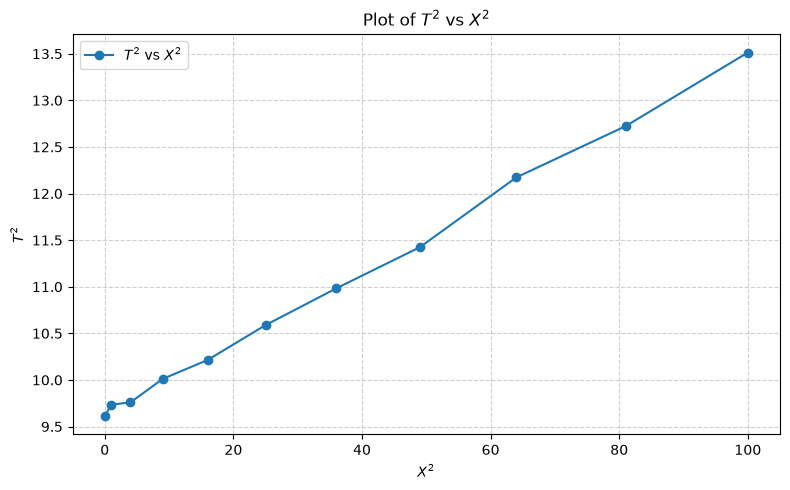

In [2]:
import matplotlib.pyplot as plt

# Data: first column is T, second column is X
T = [3.1, 3.124, 3.196, 3.12, 3.164, 3.254, 3.314, 3.38, 3.489, 3.567, 3.676]
X = [0, 2, 4, 1, 3, 5, 6, 7, 8, 9, 10]

# Compute T^2 and X^2
T2 = [t**2 for t in T]
X2 = [x**2 for x in X]

# Sort by X^2 so the line/curve is drawn in order
pairs = sorted(zip(X2, T2))
X2_sorted, T2_sorted = zip(*pairs)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(X2_sorted, T2_sorted, 'o-', color='tab:blue', label=r'$T^2$ vs $X^2$')
plt.xlabel(r'$X^2$')
plt.ylabel(r'$T^2$')
plt.title(r'Plot of $T^2$ vs $X^2$')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

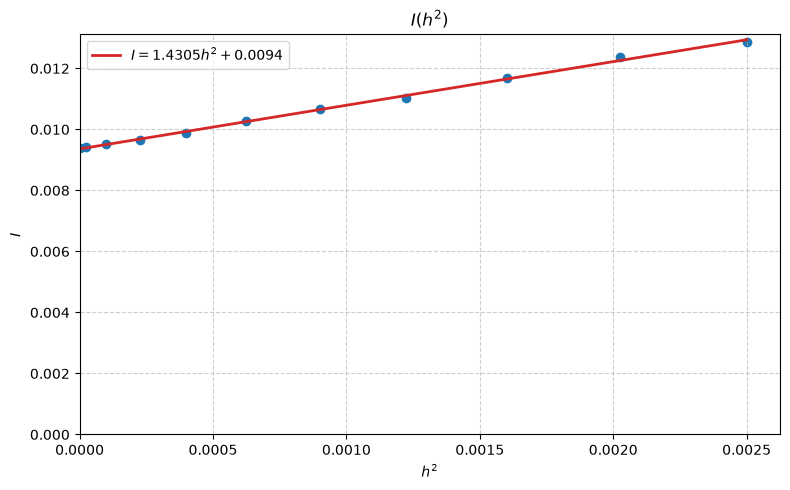

Slope = 1.430535
Intercept = 0.009361


In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Data
T = [3.10, 3.104, 3.1188, 3.144, 3.178, 3.243, 3.304, 3.358, 3.459, 3.556, 3.629]
X = [0, 1, 2, 3, 4, 5, 6, 7,8, 9, 10]

k = 0.403 * 10**(-3)
# Compute T² and X²
T2 = k * (0.9832 + 1.4419) * (np.array(T) ** 2)
X2 = (np.array(X) * 0.5/100) ** 2

# Best-fit line
m, b = np.polyfit(X2, T2, 1)

# Line values
X2_fit = np.linspace(0, max(X2), 100)
T2_fit = m * X2_fit + b

# Plot
plt.figure(figsize=(8, 5))

# Scatter the measured points
plt.scatter(X2, T2, color='tab:blue')

# Best-fit line
plt.plot(
    X2_fit,
    T2_fit,
    color='tab:red',
    linewidth=2,
    label=fr'$I = {m:.4f}h^2 + {b:.4f}$'
)

# Make origin visible
plt.xlim(left=0)
plt.ylim(bottom=0)

plt.xlabel(r'$h^2$')
plt.ylabel(r'$I$')
plt.title(r'$I(h^2)$')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()

plt.savefig("1.2.3.pdf")
plt.show()

print(f"Slope = {m:.6f}")
print(f"Intercept = {b:.6f}")

In [4]:
import numpy as np

T = np.array([3.10, 3.104, 3.1188, 3.144, 3.178, 3.243, 3.304, 3.358, 3.459, 3.556, 3.629])
X = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10])

T2 = T**2
X2 = X**2

# Linear fit
coeffs = np.polyfit(X2, T2, 1)          # slope, intercept
fit = np.polyval(coeffs, X2)

# R^2
ss_res = np.sum((T2 - fit)**2)
ss_tot = np.sum((T2 - T2.mean())**2)
r2 = 1 - ss_res/ss_tot

print(f"slope     = {coeffs[0]:.6f}")
print(f"intercept = {coeffs[1]:.6f}")
print(f"R^2       = {r2:.5f}")
print("Residuals:", np.round(T2 - fit, 4))

slope     = 0.036593
intercept = 9.577885
R^2       = 0.99791
Residuals: [ 0.0321  0.0203  0.0027 -0.0225 -0.0637  0.0243  0.0212 -0.0948  0.0448
  0.1032 -0.0676]


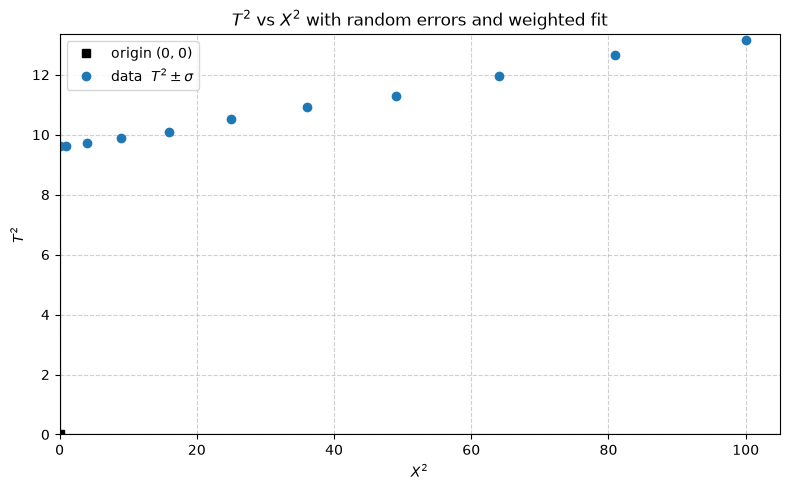

slope     = 0.03659 ± 0.00056
intercept = 9.57789 ± 0.02679


NameError: name 'r2' is not defined

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Data ---------------------------------------------------------------
T = np.array([3.10, 3.104, 3.1188, 3.144, 3.178, 3.243,
              3.304, 3.358, 3.459, 3.556, 3.629])
X = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10])

X2      = X**2
T2 = T**2

# ---- Weighted best fit:  T^2 = a*X^2 + b --------------------------------
coeffs, cov = np.polyfit(X2, T2, 1, cov=True)
a, b = coeffs
fit = a * X2 + b

# ---- Plot ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))

ax.errorbar(X2, T2, fmt='o', color='tab:blue',
            ecolor='gray', elinewidth=1, capsize=4,
            label='data  $T^2 \\pm \\sigma$')

# Smooth line over the full range, extended back to x = 0
x_smooth = np.linspace(0, X2.max(), 200)


# ---- Force (0, 0) to be visible ----------------------------------------
ax.set_xlim(left=0)                       # x-axis starts at 0
ax.set_ylim(bottom=0)                     # y-axis starts at 0
ax.axhline(0, color='k', lw=0.8)          # optional: draw the x-axis line
ax.axvline(0, color='k', lw=0.8)          # optional: draw the y-axis line
ax.plot(0, 0, 'ks', ms=6, zorder=5,
        label='origin (0, 0)')            # mark the origin itself

ax.set_xlabel(r'$X^2$')
ax.set_ylabel(r'$T^2$')
ax.set_title(r'$T^2$ vs $X^2$ with random errors and weighted fit')
ax.grid(True, ls='--', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

# ---- Print fit parameters ----------------------------------------------
da, db = np.sqrt(np.diag(cov))
print(f"slope     = {a:.5f} ± {da:.5f}")
print(f"intercept = {b:.5f} ± {db:.5f}")
print(f"R^2       = {r2:.5f}")